# Notebook 6 – Outlier Treatment

## 1. Outlier vs error
An outlier is unusual relative to a distribution; an error is an incorrect value. A high monthly charge may be valid, while a negative charge may be a data error depending on the business definition. Never automatically remove every outlier.

,MonthlyCharges
count,10.00000
mean,99.40000
std,140.89886
min,45.00000
25%,50.50000
50%,56.00000
75%,61.50000
max,500.00000


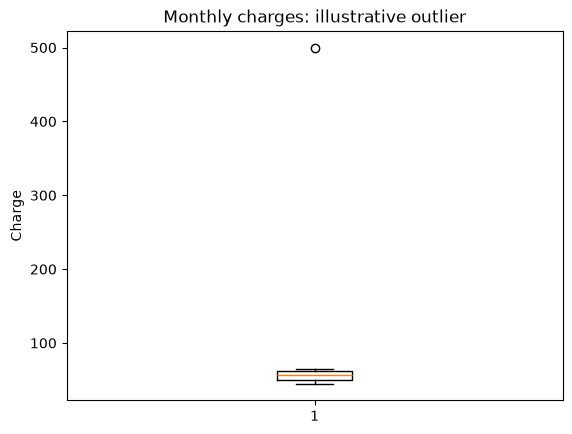

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.DataFrame({"MonthlyCharges": [45, 48, 50, 52, 55, 57, 60, 62, 65, 500]})
display(df.describe())
plt.boxplot(df["MonthlyCharges"])
plt.title("Monthly charges: illustrative outlier")
plt.ylabel("Charge")
plt.show()

**Output explanation:** The box plot and summary show an extreme value. They do not establish whether it is erroneous; investigate the source and business context.

## 2. IQR method
IQR = Q3 − Q1. A common flagging rule marks values below Q1 − 1.5×IQR or above Q3 + 1.5×IQR. This is a detection rule, not an automatic deletion rule.

In [4]:
q1 = df["MonthlyCharges"].quantile(0.25)
q3 = df["MonthlyCharges"].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
mask_iqr = ~df["MonthlyCharges"].between(lower, upper)
print("Bounds:", lower, upper)
display(df[mask_iqr])

Bounds: 34.0 78.0


,MonthlyCharges
9,500


## 3. Z-score and percentile methods
Z-score measures distance from the mean in standard deviations and can be distorted by skew/outliers. Percentile thresholds flag values outside selected quantiles; choose percentiles based on domain needs.

In [5]:
from scipy.stats import zscore

values = df["MonthlyCharges"]
z = pd.Series(zscore(values, nan_policy="omit"), index=values.index)
print("Z-score flags (absolute z > 3):", df.index[z.abs() > 3].tolist())
low, high = values.quantile([0.01, 0.99])
print("1st/99th percentile bounds:", low, high)
print("Percentile flags:", df.index[~values.between(low, high)].tolist())

Z-score flags (absolute z > 3): []
1st/99th percentile bounds: 45.27 460.8500000000001
Percentile flags: [0, 9]


## 4. Capping, flooring, winsorization, and transformation
Capping limits values above an upper bound; flooring limits values below a lower bound. Winsorization replaces extreme tails with chosen percentile bounds. Log or power transformations can reduce right skew, but require checking domain restrictions and interpretability.

In [6]:
capped = values.clip(lower=lower, upper=upper)
floored = values.clip(lower=50)
winsorized = values.clip(lower=values.quantile(0.05), upper=values.quantile(0.95))
log_transformed = np.log1p(values)

comparison = pd.DataFrame({
    "original": values,
    "capped_IQR": capped,
    "floored_at_50": floored,
    "winsorized_5_95": winsorized,
    "log1p": log_transformed
})
display(comparison)

,original,capped_IQR,floored_at_50,winsorized_5_95,log1p
0,45,45,50,46.35,3.828641
1,48,48,50,48.00,3.891820
2,50,50,50,50.00,3.931826
3,52,52,52,52.00,3.970292
4,55,55,55,55.00,4.025352
5,57,57,57,57.00,4.060443
6,60,60,60,60.00,4.110874
7,62,62,62,62.00,4.143135
8,65,65,65,65.00,4.189655
9,500,78,500,304.25,6.216606


**Output explanation:** These columns show different treatments. Choose only after determining whether extremes are valid and whether the algorithm benefits from treatment. Log transformation changes the scale and interpretation.

## 5. Remove or retain outliers?
For each flagged value, document: Is it an error? Is it valid? Should it be removed, capped, transformed, or retained? Why? Consider business value, sample size, algorithm sensitivity, and whether the value occurs in production.